In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("amazon_cleaned.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Product IDs:", df["product_id"].duplicated().sum())

Dataset Shape: (1348, 16)

Column Names:
['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']

Missing Values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
user_id                0
user_name              0
review_id              0
review_title           0
review_content         0
img_link               0
product_link           0
dtype: int64

Duplicate Product IDs: 0


In [2]:
features = [
    "actual_price",
    "discounted_price",
    "discount_percentage",
    "rating",
    "rating_count"
]

print(df[features].describe().round(2))

       actual_price  discounted_price  discount_percentage   rating  \
count       1348.00           1348.00              1348.00  1348.00   
mean        5700.51           3310.27                46.66     4.09   
std        11229.36           7180.90                21.61     0.30   
min           39.00             39.00                 0.00     2.00   
25%          899.00            349.00                31.00     3.90   
50%         1795.00            899.00                49.00     4.10   
75%         4592.50           2184.00                62.00     4.30   
max       139900.00          77990.00                94.00     5.00   

       rating_count  
count       1348.00  
mean       17656.85  
std        42158.84  
min            2.00  
25%         1107.50  
50%         4740.00  
75%        16051.50  
max       426973.00  


In [3]:
Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

iqr_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower_Bound": lower_bound,
    "Upper_Bound": upper_bound
})

print(iqr_summary.round(2))

                         Q1       Q3      IQR  Lower_Bound  Upper_Bound
actual_price          899.0   4592.5   3693.5     -4641.25     10132.75
discounted_price      349.0   2184.0   1835.0     -2403.50      4936.50
discount_percentage    31.0     62.0     31.0       -15.50       108.50
rating                  3.9      4.3      0.4         3.30         4.90
rating_count         1107.5  16051.5  14944.0    -21308.50     38467.50


In [4]:
iqr_flags = (df[features] < lower_bound) | (df[features] > upper_bound)

outlier_counts = iqr_flags.sum()

outlier_summary = pd.DataFrame({
    "Outlier_Count": outlier_counts,
    "Outlier_Percentage": outlier_counts / len(df) * 100
})

print(outlier_summary.round(2))

                     Outlier_Count  Outlier_Percentage
actual_price                   185               13.72
discounted_price               209               15.50
discount_percentage              0                0.00
rating                          17                1.26
rating_count                   130                9.64


In [5]:
df["IQR_Anomaly"] = iqr_flags.any(axis=1)

df["IQR_Outlier_Features"] = iqr_flags.sum(axis=1)

print("Total Products:", len(df))
print("IQR Anomalies:", df["IQR_Anomaly"].sum())
print("Normal Products:", (~df["IQR_Anomaly"]).sum())

print("\nAnomaly Percentage:")
print(round(df["IQR_Anomaly"].mean() * 100, 2))

Total Products: 1348
IQR Anomalies: 350
Normal Products: 998

Anomaly Percentage:
25.96


In [6]:
iqr_anomalies = df[df["IQR_Anomaly"]].copy()

top_iqr = iqr_anomalies.sort_values(
    by=["IQR_Outlier_Features", "rating_count"],
    ascending=[False, False]
)

display(top_iqr[
    [
        "product_name",
        "category",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count",
        "IQR_Outlier_Features"
    ]
].head(15))

,product_name,category,actual_price,discounted_price,discount_percentage,rating,rating_count,IQR_Outlier_Features
367,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",Electronics|Mobiles&Accessories|Smartphones&Ba...,10999.0,8499.0,23,4.1,313836,3
439,"OPPO A31 (Mystery Black, 6GB RAM, 128GB Storag...",Electronics|Mobiles&Accessories|Smartphones&Ba...,15990.0,12490.0,22,4.2,58506,3
478,"Samsung Galaxy M32 Prime Edition (Light Blue, ...",Electronics|Mobiles&Accessories|Smartphones&Ba...,13499.0,12999.0,4,4.1,56098,3
416,"Redmi Note 11 (Space Black, 4GB RAM, 64GB Stor...",Electronics|Mobiles&Accessories|Smartphones&Ba...,17999.0,12999.0,28,4.1,50772,3
481,"Redmi Note 11 (Horizon Blue, 6GB RAM, 64GB Sto...",Electronics|Mobiles&Accessories|Smartphones&Ba...,18999.0,12999.0,32,4.1,50772,3
487,"Redmi Note 11 (Space Black, 6GB RAM, 64GB Stor...",Electronics|Mobiles&Accessories|Smartphones&Ba...,18999.0,12999.0,32,4.1,50772,3
529,"Redmi Note 11 (Horizon Blue, 6GB RAM, 64GB Sto...",Electronics|Mobiles&Accessories|Smartphones&Ba...,18999.0,12999.0,32,4.1,50772,3
64,Redmi 80 cm (32 inches) Android 11 Series HD R...,"Electronics|HomeTheater,TV&Video|Televisions|S...",24999.0,13999.0,44,4.2,45238,3
72,Redmi 108 cm (43 inches) 4K Ultra HD Android S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",42999.0,26999.0,37,4.2,45238,3
124,Redmi 126 cm (50 inches) 4K Ultra HD Android S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",44999.0,32999.0,27,4.2,45238,3


In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

X = df[features].copy()

print(X.isnull().sum())

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)

actual_price           0
discounted_price       0
discount_percentage    0
rating                 0
rating_count           0
dtype: int64
Scaled Data Shape: (1348, 5)


In [8]:
iso_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

df["IF_Prediction"] = iso_model.fit_predict(X_scaled)

df["IF_Anomaly"] = df["IF_Prediction"] == -1

df["IF_Anomaly_Score"] = iso_model.decision_function(X_scaled)

print(df["IF_Anomaly"].value_counts())

print("Total Isolation Forest Anomalies:", df["IF_Anomaly"].sum())

IF_Anomaly
False    1280
True       68
Name: count, dtype: int64
Total Isolation Forest Anomalies: 68


In [9]:
both = df["IQR_Anomaly"] & df["IF_Anomaly"]

iqr_only = df["IQR_Anomaly"] & ~df["IF_Anomaly"]

if_only = ~df["IQR_Anomaly"] & df["IF_Anomaly"]

neither = ~df["IQR_Anomaly"] & ~df["IF_Anomaly"]

comparison = pd.DataFrame({
    "Category": [
        "IQR Anomalies",
        "Isolation Forest Anomalies",
        "Detected by Both",
        "IQR Only",
        "Isolation Forest Only",
        "Normal by Both"
    ],
    "Product_Count": [
        df["IQR_Anomaly"].sum(),
        df["IF_Anomaly"].sum(),
        both.sum(),
        iqr_only.sum(),
        if_only.sum(),
        neither.sum()
    ]
})

display(comparison)

,Category,Product_Count
0,IQR Anomalies,350
1,Isolation Forest Anomalies,68
2,Detected by Both,68
3,IQR Only,282
4,Isolation Forest Only,0
5,Normal by Both,998


In [10]:
agreement = (
    (df["IQR_Anomaly"] == df["IF_Anomaly"]).mean() * 100
)

union = (df["IQR_Anomaly"] | df["IF_Anomaly"]).sum()

intersection = both.sum()

jaccard = intersection / union if union > 0 else 1.0

print("Overall Agreement:", round(agreement, 2), "%")
print("Jaccard Similarity:", round(jaccard, 3))

Overall Agreement: 79.08 %
Jaccard Similarity: 0.194


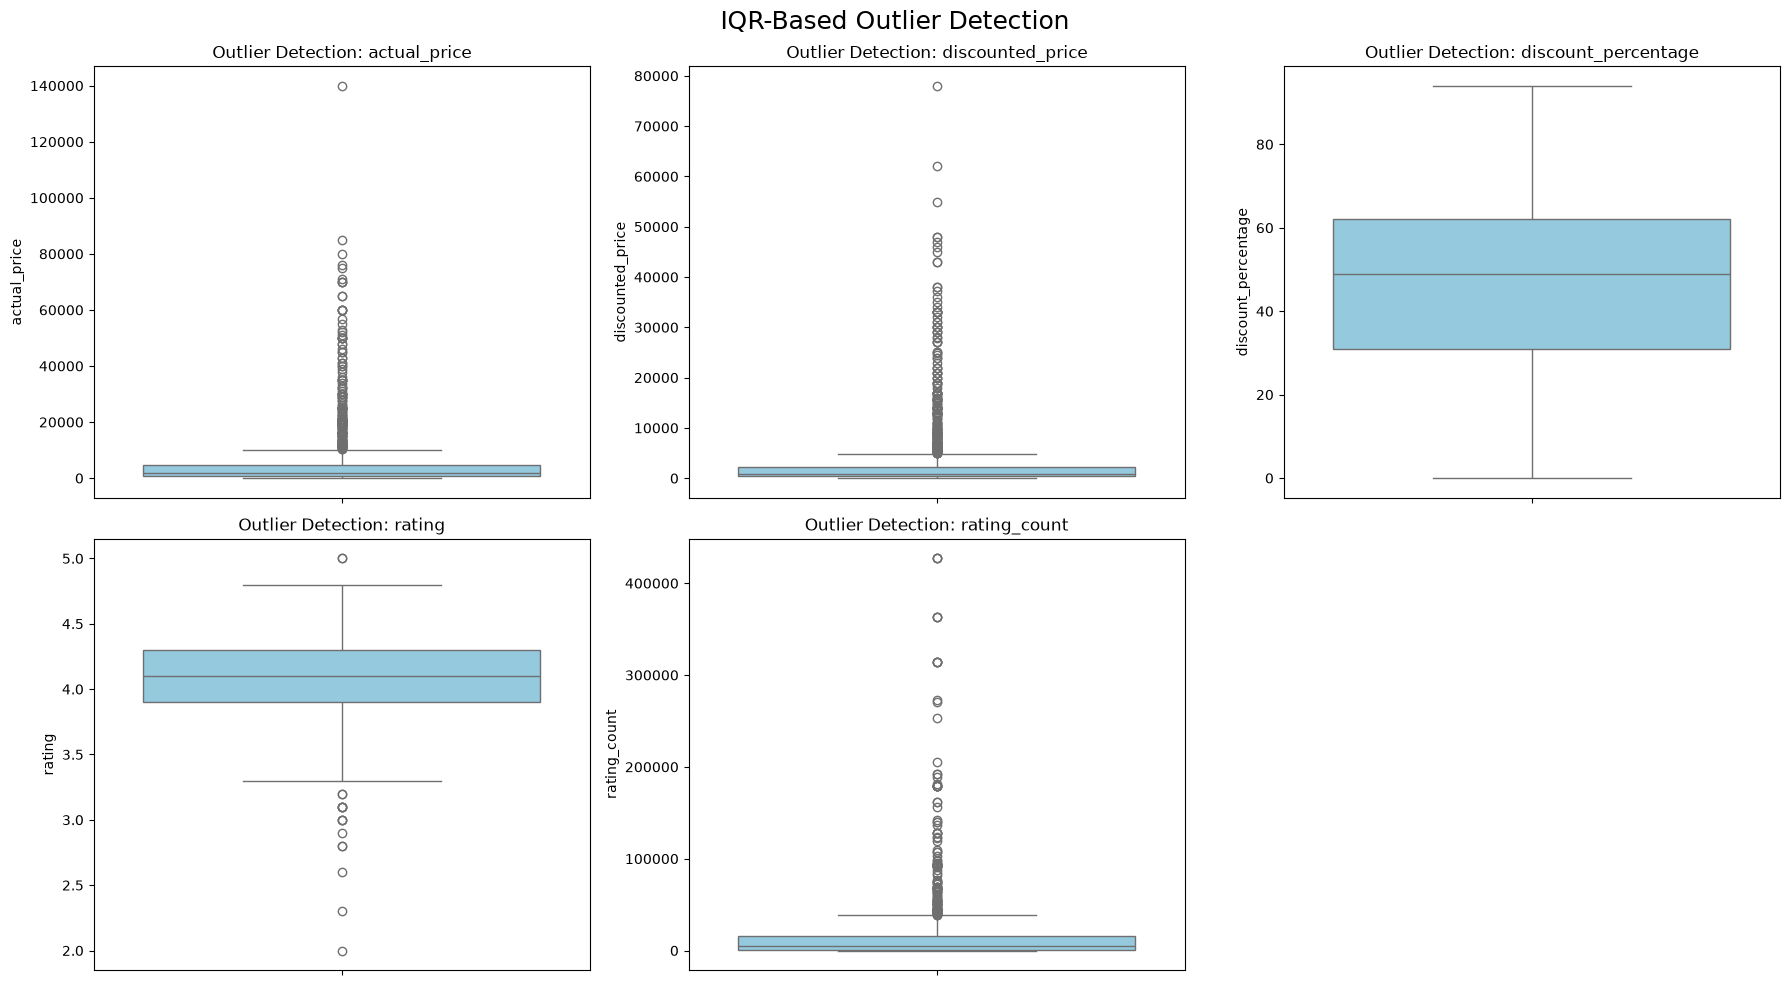

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue",
        showfliers=True
    )

    axes[i].set_title(f"Outlier Detection: {col}")
    axes[i].set_ylabel(col)

axes[5].axis("off")

plt.suptitle("IQR-Based Outlier Detection", fontsize=18)
plt.tight_layout()
plt.show()

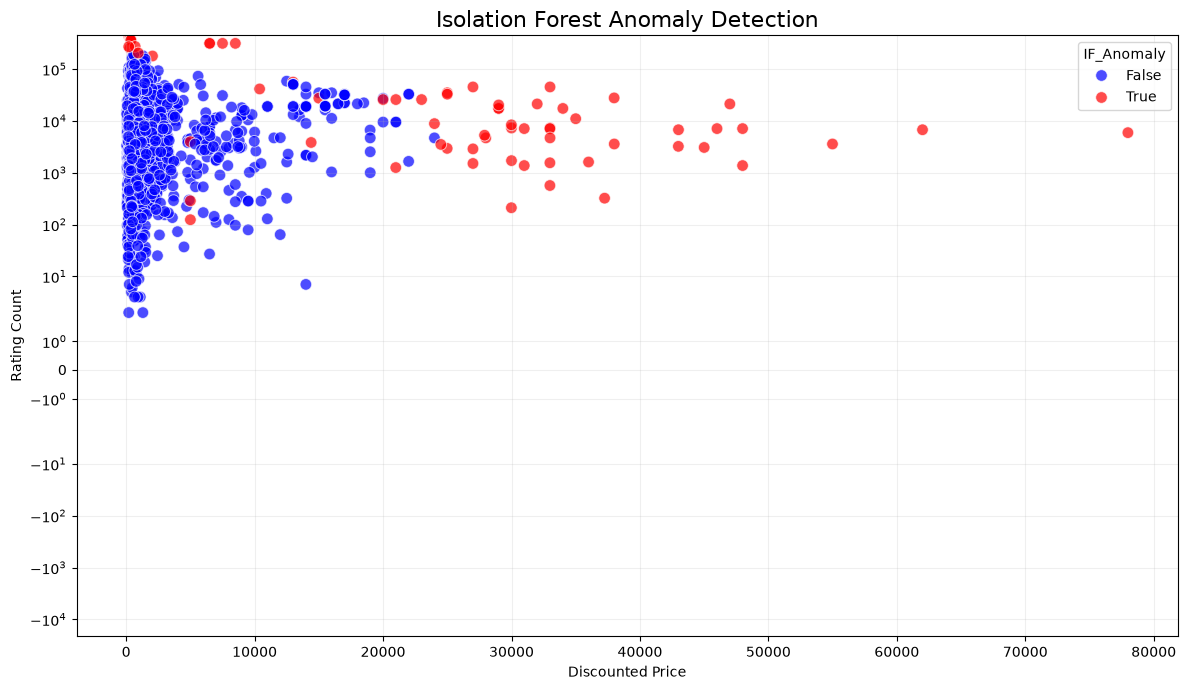

In [12]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="discounted_price",
    y="rating_count",
    hue="IF_Anomaly",
    palette={False: "blue", True: "red"},
    alpha=0.7,
    s=70
)

plt.title("Isolation Forest Anomaly Detection", fontsize=16)
plt.xlabel("Discounted Price")
plt.ylabel("Rating Count")
plt.yscale("symlog")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

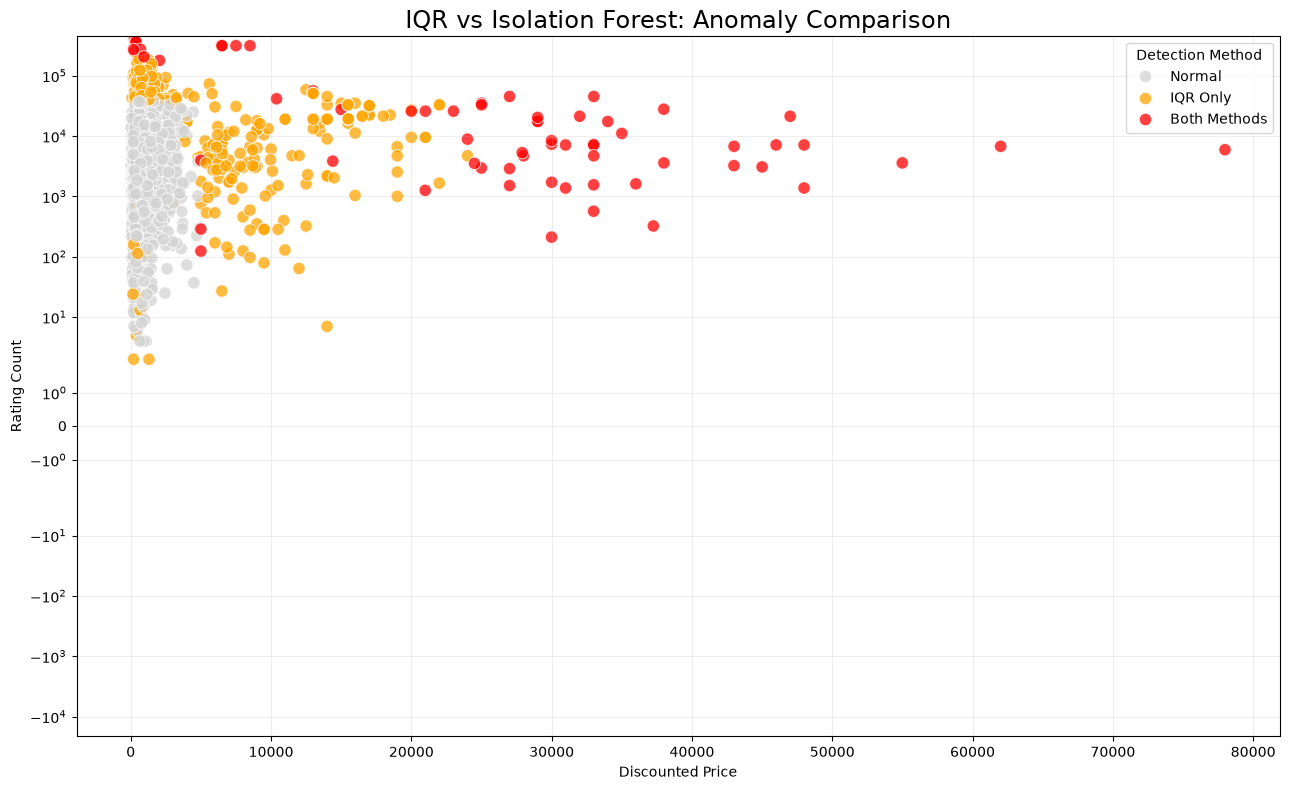

In [13]:
df["Anomaly_Type"] = np.select(
    [
        df["IQR_Anomaly"] & df["IF_Anomaly"],
        df["IQR_Anomaly"] & ~df["IF_Anomaly"],
        ~df["IQR_Anomaly"] & df["IF_Anomaly"]
    ],
    [
        "Both Methods",
        "IQR Only",
        "Isolation Forest Only"
    ],
    default="Normal"
)

plt.figure(figsize=(13, 8))

sns.scatterplot(
    data=df,
    x="discounted_price",
    y="rating_count",
    hue="Anomaly_Type",
    palette={
        "Normal": "lightgray",
        "IQR Only": "orange",
        "Isolation Forest Only": "blue",
        "Both Methods": "red"
    },
    s=80,
    alpha=0.75
)

plt.yscale("symlog")
plt.title("IQR vs Isolation Forest: Anomaly Comparison", fontsize=17)
plt.xlabel("Discounted Price")
plt.ylabel("Rating Count")
plt.legend(title="Detection Method")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

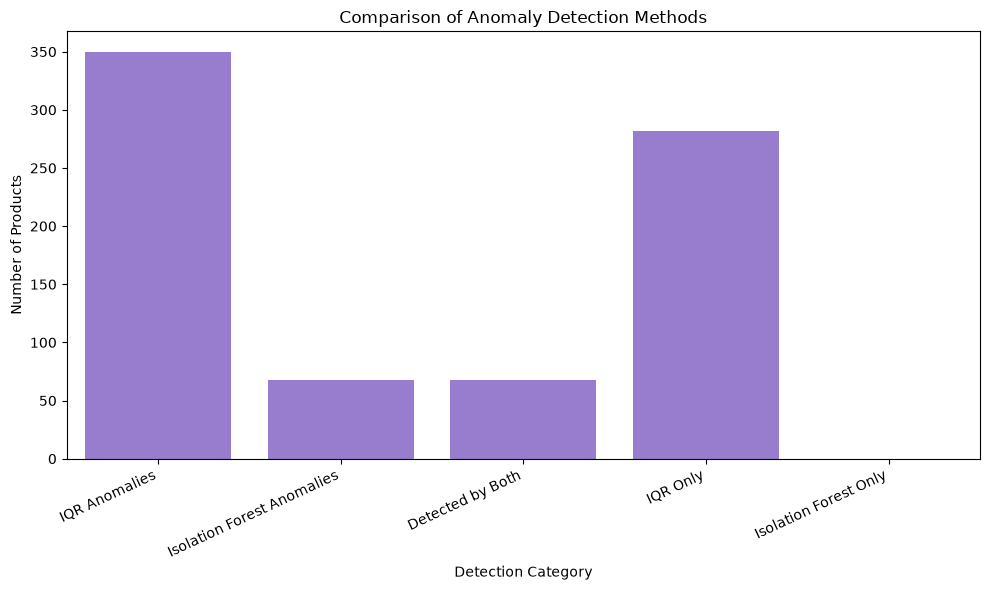

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison.iloc[:5],
    x="Category",
    y="Product_Count",
    color="mediumpurple"
)

plt.title("Comparison of Anomaly Detection Methods")
plt.xlabel("Detection Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [15]:
anomaly_products = df[
    df["IQR_Anomaly"] | df["IF_Anomaly"]
].copy()

anomaly_products["Anomaly_Priority"] = np.select(
    [
        anomaly_products["Anomaly_Type"] == "Both Methods",
        anomaly_products["Anomaly_Type"] == "Isolation Forest Only",
        anomaly_products["Anomaly_Type"] == "IQR Only"
    ],
    [1, 2, 3],
    default=4
)

anomaly_products = anomaly_products.sort_values(
    by=["Anomaly_Priority", "IF_Anomaly_Score"],
    ascending=[True, True]
)

print("Total Unique Anomalous Products:", len(anomaly_products))

display(anomaly_products[
    [
        "product_name",
        "category",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count",
        "Anomaly_Type",
        "IF_Anomaly_Score"
    ]
].head(20))

Total Unique Anomalous Products: 350


,product_name,category,actual_price,discounted_price,discount_percentage,rating,rating_count,Anomaly_Type,IF_Anomaly_Score
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",139900.0,77990.0,44,4.7,5935,Both Methods,-0.185812
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,61999.0,11,4.1,6753,Both Methods,-0.171450
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",85000.0,54990.0,35,4.3,3587,Both Methods,-0.140768
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,"Electronics|HomeTheater,TV&Video|Televisions|S...",79990.0,47990.0,40,4.3,1376,Both Methods,-0.136955
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",Electronics|Mobiles&Accessories|Smartphones&Ba...,74999.0,37990.0,49,4.2,27790,Both Methods,-0.134037
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,46999.0,33,4.3,21252,Both Methods,-0.132979
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,"Electronics|HomeTheater,TV&Video|Televisions|S...",70900.0,47990.0,32,4.3,7109,Both Methods,-0.125871
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",59999.0,42999.0,28,4.1,6753,Both Methods,-0.123577
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69900.0,45999.0,34,4.3,7109,Both Methods,-0.121809
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",Electronics|Mobiles&Accessories|Smartphones&Ba...,49999.0,44999.0,10,4.3,3075,Both Methods,-0.121648


In [16]:
price_q95 = df["actual_price"].quantile(0.95)
rating_count_q95 = df["rating_count"].quantile(0.95)
discount_q95 = df["discount_percentage"].quantile(0.95)

def classify_anomaly(row):
    if (
        row["actual_price"] <= 0
        or row["discounted_price"] <= 0
        or row["discounted_price"] > row["actual_price"]
        or not 0 <= row["discount_percentage"] <= 100
        or not 0 <= row["rating"] <= 5
        or row["rating_count"] < 0
    ):
        return "Possible Database Error"

    if (
        row["discount_percentage"] >= discount_q95
        and row["discount_percentage"] >= 70
    ):
        return "Suspicious Discount"

    if row["actual_price"] >= price_q95:
        return "Legitimate Premium Product - Review Needed"

    if row["rating_count"] >= rating_count_q95:
        return "Unusually Popular Product"

    if row["rating"] >= 4.3 and row["rating_count"] >= df["rating_count"].median():
        return "Potential Commercial Opportunity"

    return "Requires Manual Investigation"

anomaly_products["Business_Classification"] = anomaly_products.apply(
    classify_anomaly,
    axis=1
)

display(anomaly_products[
    [
        "product_name",
        "category",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count",
        "Business_Classification"
    ]
].head(20))

,product_name,category,actual_price,discounted_price,discount_percentage,rating,rating_count,Business_Classification
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",139900.0,77990.0,44,4.7,5935,Legitimate Premium Product - Review Needed
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,61999.0,11,4.1,6753,Legitimate Premium Product - Review Needed
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",85000.0,54990.0,35,4.3,3587,Legitimate Premium Product - Review Needed
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,"Electronics|HomeTheater,TV&Video|Televisions|S...",79990.0,47990.0,40,4.3,1376,Legitimate Premium Product - Review Needed
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",Electronics|Mobiles&Accessories|Smartphones&Ba...,74999.0,37990.0,49,4.2,27790,Legitimate Premium Product - Review Needed
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,46999.0,33,4.3,21252,Legitimate Premium Product - Review Needed
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,"Electronics|HomeTheater,TV&Video|Televisions|S...",70900.0,47990.0,32,4.3,7109,Legitimate Premium Product - Review Needed
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",59999.0,42999.0,28,4.1,6753,Legitimate Premium Product - Review Needed
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69900.0,45999.0,34,4.3,7109,Legitimate Premium Product - Review Needed
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",Electronics|Mobiles&Accessories|Smartphones&Ba...,49999.0,44999.0,10,4.3,3075,Legitimate Premium Product - Review Needed


,Business_Classification,Product_Count
0,Requires Manual Investigation,165
1,Legitimate Premium Product - Review Needed,70
2,Unusually Popular Product,67
3,Potential Commercial Opportunity,35
4,Suspicious Discount,13


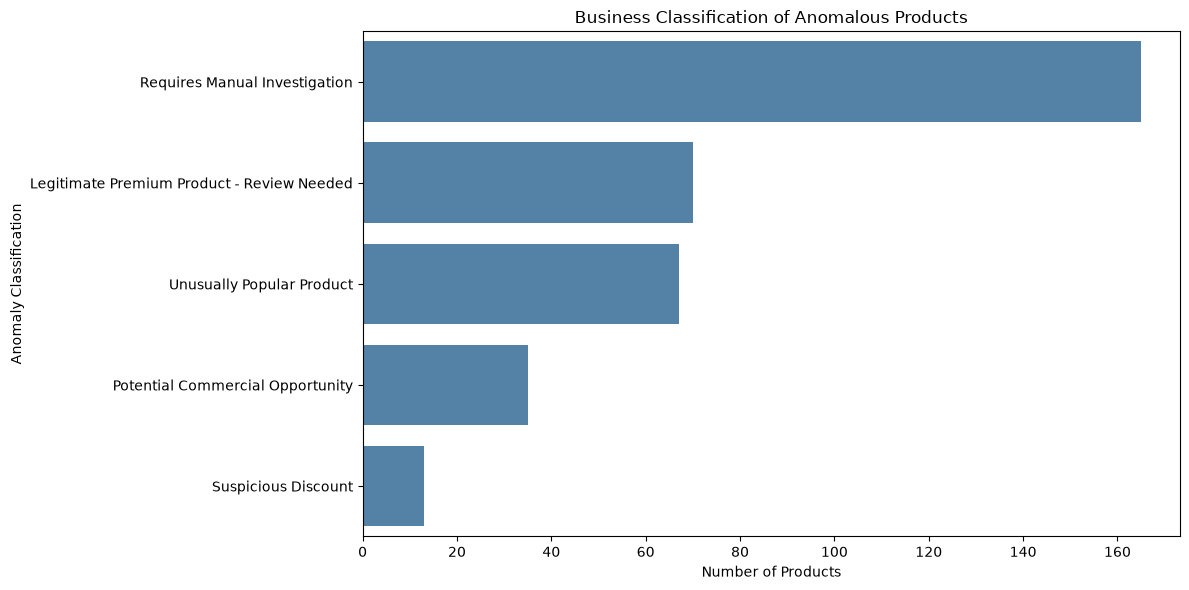

In [17]:
classification_summary = (
    anomaly_products["Business_Classification"]
    .value_counts()
    .reset_index()
)

classification_summary.columns = [
    "Business_Classification",
    "Product_Count"
]

display(classification_summary)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classification_summary,
    x="Product_Count",
    y="Business_Classification",
    color="steelblue"
)

plt.title("Business Classification of Anomalous Products")
plt.xlabel("Number of Products")
plt.ylabel("Anomaly Classification")
plt.tight_layout()
plt.show()

In [18]:
review_columns = [
    col for col in [
        "product_name",
        "category",
        "rating",
        "rating_count",
        "review_title",
        "review_content",
        "Business_Classification"
    ]
    if col in anomaly_products.columns
]

display(anomaly_products[review_columns].head(15))

,product_name,category,rating,rating_count,review_title,review_content,Business_Classification
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.7,5935,Product installation was excellent but deliver...,The delivery people were not careful with the ...,Legitimate Premium Product - Review Needed
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.1,6753,"Almost Perfect!,Review After using 1month,Nice...",Update after 9 months of use:1. The TV is stil...,Legitimate Premium Product - Review Needed
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.3,3587,Good TV for the price. (But my experience was ...,",Screen quality is good.It's been a month I bo...",Legitimate Premium Product - Review Needed
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.3,1376,"Love Amazon but lg is misleading,Amazing produ...",There's no magic remote and lg should include ...,Legitimate Premium Product - Review Needed
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",Electronics|Mobiles&Accessories|Smartphones&Ba...,4.2,27790,"WORTH BUY ! THE BEST,Good for the price.",It's been 15 days since i using the device ext...,Legitimate Premium Product - Review Needed
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.3,21252,"It's super,Value of money 💰,Display and build,...","It's very good peace what I read.,Institutions...",Legitimate Premium Product - Review Needed
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.3,7109,"Best(Branded) Budget TV,A high-quality 4k Smar...","Before finalizing the AUE60 55"", I visited Cro...",Legitimate Premium Product - Review Needed
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.1,6753,"Almost Perfect!,Review After using 1month,Nice...",Update after 9 months of use:1. The TV is stil...,Legitimate Premium Product - Review Needed
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,"Electronics|HomeTheater,TV&Video|Televisions|S...",4.3,7109,"Best(Branded) Budget TV,A high-quality 4k Smar...","Before finalizing the AUE60 55"", I visited Cro...",Legitimate Premium Product - Review Needed
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",Electronics|Mobiles&Accessories|Smartphones&Ba...,4.3,3075,"A conditional beast,Overall satisfied but Wow ...","Liked - Top notch display, gorgeous display, h...",Legitimate Premium Product - Review Needed


In [19]:
repeated_reviews = (
    df.groupby(["rating_count", "review_content"])
    .agg(
        Product_Count=("product_name", "count"),
        Product_Names=("product_name", list)
    )
    .reset_index()
)

repeated_reviews = repeated_reviews[
    repeated_reviews["Product_Count"] > 1
]

display(
    repeated_reviews.sort_values(
        "Product_Count",
        ascending=False
    ).head(10)
)

,rating_count,review_content,Product_Count,Product_Names
981,18998,"I am not big on camera usage, personally. I wa...",8,"[Samsung Galaxy M13 (Aqua Green, 6GB, 128GB St..."
905,13937,"I liked it, worth the money, light weight and ...",5,"[Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wa..."
982,19252,I purchased the 6/128gb variant.To sum it up i...,5,"[iQOO Z6 Lite 5G by vivo (Stellar Green, 6GB R..."
808,9378,Worked on iPhone 7 and didn’t work on iPhone X...,4,"[Flix Micro Usb Cable For Smartphone (Black), ..."
1173,94363,"Good product,long wire,Charges good,Nice,I bou...",4,[boAt Deuce USB 300 2 in 1 Type-C & Micro USB ...
1130,50772,I was looking for a phone below 10K. I am not ...,4,"[Redmi Note 11 (Space Black, 4GB RAM, 64GB Sto..."
1184,128311,Phone is ok except middle button it’s a headac...,4,"[Nokia 105 Single SIM, Keypad Mobile Phone wit..."
726,7109,"Before finalizing the AUE60 55"", I visited Cro...",4,[Samsung 108 cm (43 inches) Crystal 4K Neo Ser...
515,2806,"Material os very good, initially charges very ...",4,[Wayona Type C To Type C Long Fast Charging Ca...
638,4703,About the TV - Wonderful----------------------...,4,[Acer 80 cm (32 inches) I Series HD Ready Andr...


In [20]:
display(
    anomaly_products[
        [
            "product_name",
            "category",
            "actual_price",
            "discounted_price",
            "discount_percentage",
            "rating",
            "rating_count",
            "Business_Classification"
        ]
    ].head(20)
)

,product_name,category,actual_price,discounted_price,discount_percentage,rating,rating_count,Business_Classification
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",139900.0,77990.0,44,4.7,5935,Legitimate Premium Product - Review Needed
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,61999.0,11,4.1,6753,Legitimate Premium Product - Review Needed
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",85000.0,54990.0,35,4.3,3587,Legitimate Premium Product - Review Needed
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,"Electronics|HomeTheater,TV&Video|Televisions|S...",79990.0,47990.0,40,4.3,1376,Legitimate Premium Product - Review Needed
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",Electronics|Mobiles&Accessories|Smartphones&Ba...,74999.0,37990.0,49,4.2,27790,Legitimate Premium Product - Review Needed
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,46999.0,33,4.3,21252,Legitimate Premium Product - Review Needed
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,"Electronics|HomeTheater,TV&Video|Televisions|S...",70900.0,47990.0,32,4.3,7109,Legitimate Premium Product - Review Needed
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",59999.0,42999.0,28,4.1,6753,Legitimate Premium Product - Review Needed
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69900.0,45999.0,34,4.3,7109,Legitimate Premium Product - Review Needed
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",Electronics|Mobiles&Accessories|Smartphones&Ba...,49999.0,44999.0,10,4.3,3075,Legitimate Premium Product - Review Needed


In [21]:
df["Calculated_Discount"] = np.where(
    df["actual_price"] > 0,
    (df["actual_price"] - df["discounted_price"])
    / df["actual_price"] * 100,
    np.nan
)

df["Discount_Difference"] = abs(
    df["discount_percentage"] - df["Calculated_Discount"]
)

discount_errors = df[
    df["Discount_Difference"] > 1
].copy()

print("Discount Mismatch Products:", len(discount_errors))

display(discount_errors[
    [
        "product_name",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "Calculated_Discount",
        "Discount_Difference"
    ]
].head(15))

Discount Mismatch Products: 0


,product_name,actual_price,discounted_price,discount_percentage,Calculated_Discount,Discount_Difference


In [22]:
repeated_ratings = (
    df.groupby("rating_count")
    .agg(
        Product_Count=("product_name", "count"),
        Unique_Products=("product_name", "nunique")
    )
    .reset_index()
)

repeated_ratings = repeated_ratings[
    (repeated_ratings["Product_Count"] > 1)
    & (repeated_ratings["rating_count"] >= 100000)
]

display(
    repeated_ratings.sort_values(
        "rating_count",
        ascending=False
    ).head(15)
)

,rating_count,Product_Count,Unique_Products
1115,426973,3,3
1114,363713,2,2
1112,313836,2,2
1111,313832,2,2
1101,179691,2,2
1100,178912,3,3
1094,140036,2,2
1092,128311,4,4


In [23]:
anomaly_products["Investigation_Decision"] = np.select(
    [
        anomaly_products["Business_Classification"] == "Possible Database Error",
        anomaly_products["Business_Classification"] == "Suspicious Discount",
        anomaly_products["Business_Classification"] == "Legitimate Premium Product - Review Needed",
        anomaly_products["Business_Classification"] == "Unusually Popular Product",
        anomaly_products["Business_Classification"] == "Potential Commercial Opportunity"
    ],
    [
        "Flag for Data Validation",
        "Retain and Verify Discount",
        "Retain and Verify Premium Pricing",
        "Retain and Check Shared Reviews",
        "Retain for Business Analysis"
    ],
    default="Retain Pending Investigation"
)

final_anomaly_report = anomaly_products[
    [
        "product_name",
        "category",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count",
        "Anomaly_Type",
        "Business_Classification",
        "Investigation_Decision"
    ]
].copy()

display(final_anomaly_report.head(20))

,product_name,category,actual_price,discounted_price,discount_percentage,rating,rating_count,Anomaly_Type,Business_Classification,Investigation_Decision
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",139900.0,77990.0,44,4.7,5935,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,61999.0,11,4.1,6753,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,"Electronics|HomeTheater,TV&Video|Televisions|S...",85000.0,54990.0,35,4.3,3587,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,"Electronics|HomeTheater,TV&Video|Televisions|S...",79990.0,47990.0,40,4.3,1376,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",Electronics|Mobiles&Accessories|Smartphones&Ba...,74999.0,37990.0,49,4.2,27790,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69999.0,46999.0,33,4.3,21252,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,"Electronics|HomeTheater,TV&Video|Televisions|S...",70900.0,47990.0,32,4.3,7109,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,"Electronics|HomeTheater,TV&Video|Televisions|S...",59999.0,42999.0,28,4.1,6753,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,"Electronics|HomeTheater,TV&Video|Televisions|S...",69900.0,45999.0,34,4.3,7109,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",Electronics|Mobiles&Accessories|Smartphones&Ba...,49999.0,44999.0,10,4.3,3075,Both Methods,Legitimate Premium Product - Review Needed,Retain and Verify Premium Pricing


In [26]:
total_products = len(df)

iqr_count = int(df["IQR_Anomaly"].sum())
if_count = int(df["IF_Anomaly"].sum())

both_count = int(
    (df["IQR_Anomaly"] & df["IF_Anomaly"]).sum()
)

iqr_only_count = int(
    (df["IQR_Anomaly"] & ~df["IF_Anomaly"]).sum()
)

if_only_count = int(
    (~df["IQR_Anomaly"] & df["IF_Anomaly"]).sum()
)

print("Total Products:", total_products)
print("IQR Anomalies:", iqr_count)
print("Isolation Forest Anomalies:", if_count)
print("Detected by Both:", both_count)
print("IQR Only:", iqr_only_count)
print("Isolation Forest Only:", if_only_count)
print("Unique Anomalies:", len(anomaly_products))

Total Products: 1348
IQR Anomalies: 350
Isolation Forest Anomalies: 68
Detected by Both: 68
IQR Only: 282
Isolation Forest Only: 0
Unique Anomalies: 350


In [27]:
repeated_details = df[
    df["rating_count"].isin(
        repeated_ratings["rating_count"]
    )
].copy()

display(
    repeated_details[
        [
            "product_name",
            "rating_count",
            "rating",
            "review_title",
            "review_content"
        ]
    ].sort_values(
        "rating_count",
        ascending=False
    ).head(20)
)

,product_name,rating_count,rating,review_title,review_content
12,AmazonBasics Flexible Premium HDMI Cable (Blac...,426973,4.4,"It's quite good and value for money,Works well...",I am using it for 14 days now. The experience ...
47,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",426973,4.4,"It's quite good and value for money,Works well...",I am using it for 14 days now. The experience ...
65,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",426973,4.4,"It's quite good and value for money,Works well...",I am using it for 14 days now. The experience ...
350,boAt Bassheads 100 in Ear Wired Earphones with...,363713,4.1,"Best value for money,HEAD PHONE POUCH NOT RECE...",The sound quality of this earphone are really ...
393,boAt Bassheads 100 in Ear Wired Earphones with...,363713,4.1,"Best value for money,HEAD PHONE POUCH NOT RECE...",The sound quality of this earphone are really ...
368,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...",313836,4.1,"Best phone for below normal use,Good mobile fo...",If you want a smart phone for just the use of ...
367,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",313836,4.1,"Best phone for below normal use,Good mobile fo...",If you want a smart phone for just the use of ...
539,"Redmi 9A Sport (Coral Green, 3GB RAM, 32GB Sto...",313832,4.1,"Best phone for below normal use,Good mobile fo...",If you want a smart phone for just the use of ...
454,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...",313832,4.1,"Best phone for below normal use,Good mobile fo...",If you want a smart phone for just the use of ...
8,"TP-Link USB WiFi Adapter for PC(TL-WN725N), N1...",179691,4.2,Works on linux for me. Get the model with ante...,I use this to connect an old PC to internet. I...


In [28]:
validation = pd.DataFrame({
    "Check": [
        "Discount Mismatches",
        "Missing Product Names",
        "Missing Categories",
        "Invalid Ratings",
        "Negative Rating Counts",
        "Invalid Prices",
        "Automatically Removed Products"
    ],
    "Count": [
        len(discount_errors),
        df["product_name"].isna().sum(),
        df["category"].isna().sum(),
        ((df["rating"] < 0) | (df["rating"] > 5)).sum(),
        (df["rating_count"] < 0).sum(),
        (
            (df["actual_price"] <= 0) |
            (df["discounted_price"] <= 0)
        ).sum(),
        0
    ]
})

display(validation)

,Check,Count
0,Discount Mismatches,0
1,Missing Product Names,0
2,Missing Categories,0
3,Invalid Ratings,0
4,Negative Rating Counts,0
5,Invalid Prices,0
6,Automatically Removed Products,0


In [30]:
review_group_counts = df.groupby(
    ["rating_count", "review_content"],
    dropna=False
)["product_name"].transform("size")

df["Shared_Review_Flag"] = review_group_counts > 1

print("Products With Repeated Review Evidence:")
print(df["Shared_Review_Flag"].sum())

anomaly_products["Shared_Review_Flag"] = df.loc[
    anomaly_products.index,
    "Shared_Review_Flag"
]

display(
    anomaly_products[
        [
            "product_name",
            "rating_count",
            "Shared_Review_Flag",
            "Business_Classification"
        ]
    ].head(20)
)

Products With Repeated Review Evidence:
231


,product_name,rating_count,Shared_Review_Flag,Business_Classification
249,Sony Bravia 164 cm (65 inches) 4K Ultra HD Sma...,5935,False,Legitimate Premium Product - Review Needed
323,OnePlus 163.8 cm (65 inches) U Series 4K LED S...,6753,True,Legitimate Premium Product - Review Needed
255,VU 164 cm (65 inches) The GloLED Series 4K Sma...,3587,True,Legitimate Premium Product - Review Needed
282,LG 139 cm (55 inches) 4K Ultra HD Smart LED TV...,1376,True,Legitimate Premium Product - Review Needed
541,"Samsung Galaxy S20 FE 5G (Cloud Navy, 8GB RAM,...",27790,False,Legitimate Premium Product - Review Needed
330,MI 138.8 cm (55 inches) 5X Series 4K Ultra HD ...,21252,False,Legitimate Premium Product - Review Needed
192,Samsung 138 cm (55 inches) Crystal 4K Neo Seri...,7109,True,Legitimate Premium Product - Review Needed
216,OnePlus 138.7 cm (55 inches) U Series 4K LED S...,6753,True,Legitimate Premium Product - Review Needed
276,Samsung 138 cm (55 inches) Crystal 4K Series U...,7109,True,Legitimate Premium Product - Review Needed
509,"OnePlus 10T 5G (Moonstone Black, 8GB RAM, 128G...",3075,False,Legitimate Premium Product - Review Needed


In [31]:
final_anomaly_report = anomaly_products[
    [
        "product_name",
        "category",
        "actual_price",
        "discounted_price",
        "discount_percentage",
        "rating",
        "rating_count",
        "Anomaly_Type",
        "IF_Anomaly_Score",
        "Shared_Review_Flag",
        "Business_Classification",
        "Investigation_Decision"
    ]
].copy()

final_anomaly_report.to_csv(
    "task_5_final_anomaly_report.csv",
    index=False
)

print("Updated Final Anomaly Report Saved")

Updated Final Anomaly Report Saved


# Task 5: Anomaly and Outlier Detection – Final Conclusion

The Amazon Product Analytics dataset was analyzed using two anomaly detection techniques: **Interquartile Range (IQR)** and **Isolation Forest**. Five numerical features were considered: actual price, discounted price, discount percentage, rating, and rating count.

The IQR method identified products with extreme individual feature values, while Isolation Forest detected unusual combinations of multiple product characteristics. Both techniques provided complementary approaches to identifying potential anomalies.

### Key Findings

1. **Legitimate Premium Products:** High-priced products such as Sony Bravia TVs, Samsung smartphones, LG air conditioners, and Lenovo laptops were identified as potential anomalies. Their prices were plausible for their respective categories, indicating that many may be genuine premium products rather than database errors.

2. **Unusually Popular Products:** Amazon Basics HDMI cables and Redmi smartphones showed exceptionally high rating counts. Certain HDMI cables had 426,973 ratings with an average rating of 4.4, suggesting strong customer engagement and potential commercial opportunities.

3. **Suspicious Discounts:** Some products displayed unusually high discounts, including an Amazon Basics HDMI cable with a 78% discount. Although the discount calculations were mathematically consistent, such offers require verification to determine whether the original prices and discounts are genuine.

4. **Repeated Customer Reviews:** Identical ratings, rating counts, and review content were observed across multiple product listings, including HDMI cables, Redmi smartphones, Mi power banks, and Samsung memory cards. This suggests possible shared product-family reviews or duplicated review information, which could distort popularity analysis if counted independently.

5. **Data Quality Validation:** No invalid prices, invalid ratings, negative rating counts, missing product names, missing categories, or discount calculation mismatches exceeding one percentage point were detected during validation.

### Business Recommendations

- Retain legitimate premium products because their high prices may reflect genuine product characteristics.
- Investigate unusually high discounts before drawing conclusions about promotional effectiveness.
- Consider highly rated products with substantial review engagement as potential commercial opportunities.
- Flag repeated review information to avoid overstating customer demand.
- Validate suspicious records individually rather than automatically removing statistical outliers.

### Final Conclusion

The analysis demonstrated that **anomalies are not necessarily data errors; they can also represent valuable business opportunities**. Combining IQR and Isolation Forest helped identify unusual pricing, discounting, and customer engagement patterns.

No outliers were automatically removed, preserving potentially valuable observations for further investigation. The findings highlight the importance of combining statistical techniques, machine learning, data validation, and business context to support reliable, data-driven decisions.

**Overall, Task 5 successfully identified and investigated unusual product behavior while preserving data integrity and generating actionable business insights.**